In [3]:
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)

RANDOM_STATE = 42
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

NEG_RMSE = make_scorer(rmse, greater_is_better=False)

pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

In [5]:
with open('data/u.genre', encoding='latin-1') as f:
    GENRES = [line.strip().rsplit('|', 1)[0] for line in f if line.strip()]

ratings = pd.read_csv('data/u.data', sep='\t',
                      names=['user_id', 'item_id', 'rating', 'timestamp'])

item_cols = ['item_id', 'title', 'release_date', 'video_date', 'imdb_url'] + GENRES
items = pd.read_csv('data/u.item', sep='|', names=item_cols, encoding='latin-1')
items = items[['item_id', 'title'] + GENRES]

users = pd.read_csv('data/u.user', sep='|',
                    names=['user_id', 'age', 'gender', 'occupation', 'zip'],
                    encoding='latin-1')[['user_id', 'age', 'gender', 'occupation']]

print('Рейтингов:', len(ratings), '| пользователей:', ratings['user_id'].nunique(),
      '| фильмов:', ratings['item_id'].nunique())
print('Жанры (', len(GENRES), '):', GENRES)

Рейтингов: 100000 | пользователей: 943 | фильмов: 1682
Жанры ( 19 ): ['unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


In [6]:
print('Рейтингов:', len(ratings), '| пользователей:', ratings['user_id'].nunique(),
      '| фильмов:', ratings['item_id'].nunique())
print('Пропуски в ratings:\n', ratings.isnull().sum())
print('Разреженность матрицы: %.4f' % (1 - len(ratings) /
      (ratings['user_id'].nunique() * ratings['item_id'].nunique())))

for _ in range(3):
    uc = ratings.groupby('user_id').size()
    ic = ratings.groupby('item_id').size()
    ratings = ratings[ratings['user_id'].isin(uc[uc >= 5].index) &
                      ratings['item_id'].isin(ic[ic >= 5].index)]
print('После фильтрации:', len(ratings), 'рейтингов,',
      ratings['user_id'].nunique(), 'пользователей,', ratings['item_id'].nunique(), 'фильмов')

Рейтингов: 100000 | пользователей: 943 | фильмов: 1682
Пропуски в ratings:
 user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64
Разреженность матрицы: 0.9370
После фильтрации: 99287 рейтингов, 943 пользователей, 1349 фильмов


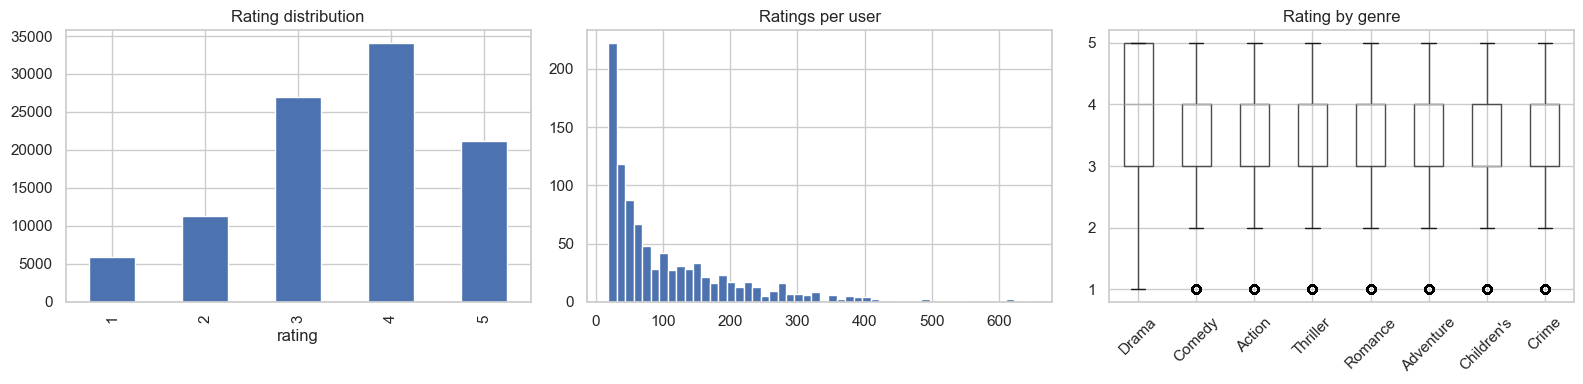

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ratings['rating'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Rating distribution')
ratings.groupby('user_id').size().hist(bins=50, ax=axes[1])
axes[1].set_title('Ratings per user')
top_genres = items[GENRES].sum().sort_values(ascending=False).head(8)
box = ratings.merge(items[['item_id'] + GENRES], on='item_id', how='left')
box_data = pd.DataFrame({g: box.loc[box[g] == 1, 'rating'] for g in top_genres.index})
box_data.boxplot(ax=axes[2])
axes[2].set_title('Rating by genre')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [8]:
train, test = train_test_split(ratings, test_size=0.2, random_state=RANDOM_STATE)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

tr_users = set(train['user_id'].unique())
tr_items = set(train['item_id'].unique())
test = test[test['user_id'].isin(tr_users) & test['item_id'].isin(tr_items)].reset_index(drop=True)
print('train:', len(train), 'test:', len(test))

users_enc = users.copy()
users_enc['gender_bin'] = (users_enc['gender'] == 'M').astype(int)
occ_map = {o: k for k, o in enumerate(sorted(users_enc['occupation'].astype(str).unique()))}
users_enc['occ_code'] = users_enc['occupation'].astype(str).map(occ_map)
users_enc = users_enc[['user_id', 'age', 'gender_bin', 'occ_code']]
items_genres = items[['item_id'] + GENRES]

train: 79429 test: 19858


In [9]:
class PairFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, users_enc, items_genres, genre_cols, content_only=False):
        self.users_enc = users_enc
        self.items_genres = items_genres
        self.genre_cols = genre_cols
        self.content_only = content_only

    def fit(self, X, y=None):
        self.mu_ = float(np.mean(y)) if y is not None else 3.0
        t = X.assign(r=y)
        self.u_mean_ = t.groupby('user_id')['r'].mean().to_dict()
        self.i_mean_ = t.groupby('item_id')['r'].mean().to_dict()
        self.u_cnt_ = t.groupby('user_id').size().to_dict()
        self.i_cnt_ = t.groupby('item_id').size().to_dict()
        return self

    def transform(self, X, y=None):
        d = X[['user_id', 'item_id']].copy()
        if not self.content_only:
            d['u_mean'] = d['user_id'].map(self.u_mean_).fillna(self.mu_)
            d['i_mean'] = d['item_id'].map(self.i_mean_).fillna(self.mu_)
            d['u_cnt'] = d['user_id'].map(self.u_cnt_).fillna(0)
            d['i_cnt'] = d['item_id'].map(self.i_cnt_).fillna(0)
        d = d.merge(self.users_enc, on='user_id', how='left')
        d = d.merge(self.items_genres, on='item_id', how='left')
        d = d.fillna(0)
        cols = [c for c in d.columns if c not in ('user_id', 'item_id')]
        self.feature_names_ = cols
        return d[cols].values.astype('float32')


pf = PairFeatures(users_enc, items_genres, GENRES)
F = pf.fit_transform(train, train['rating'])
corr = pd.DataFrame(F, columns=pf.feature_names_).corrwith(pd.Series(train['rating'].values))
print('Корреляция признаков с рейтингом:')
print(corr.abs().sort_values(ascending=False).head(8).round(3))

Корреляция признаков с рейтингом:
i_mean    0.455
u_mean    0.395
i_cnt     0.214
Drama     0.118
u_cnt     0.107
War       0.084
Comedy    0.083
age       0.054
dtype: float64


In [10]:
train_by_user = train.groupby('user_id')['item_id'].apply(list).to_dict()
test_by_user = {}
for u, i, r in zip(test['user_id'], test['item_id'], test['rating']):
    test_by_user.setdefault(u, []).append((i, r))
ALL_ITEMS = np.sort(train['item_id'].unique())


def ranking_metrics(predict_fn, k=10, thr=4, max_users=200, seed=42):
    """Precision@K и NDCG@K: релевантно = рейтинг >= thr."""
    users = [u for u in test_by_user if any(r >= thr for _, r in test_by_user[u])]
    rng = np.random.RandomState(seed)
    if len(users) > max_users:
        users = list(rng.choice(users, max_users, replace=False))
    rows = []
    for u in users:
        seen = set(train_by_user.get(u, []))
        for i in ALL_ITEMS:
            if i not in seen:
                rows.append((u, i))
    cand = pd.DataFrame(rows, columns=['user_id', 'item_id'])
    scores = np.asarray(predict_fn(cand))
    prec, ndcg = [], []
    for u in users:
        rel = set(i for i, r in test_by_user[u] if r >= thr)
        if not rel:
            continue
        m = cand['user_id'].values == u
        order = np.argsort(-scores[m])
        topk = cand['item_id'].values[m][order][:k]
        hits = [1 if i in rel else 0 for i in topk]
        prec.append(sum(hits) / k)
        dcg = sum(h / np.log2(p + 2) for p, h in enumerate(hits) if h)
        idcg = sum(1 / np.log2(j + 2) for j in range(min(k, len(rel))))
        ndcg.append(dcg / idcg if idcg > 0 else 0)
    return float(np.mean(prec)), float(np.mean(ndcg))

In [11]:
class KNNCF(BaseEstimator):
    def __init__(self, n_neighbors=20, user_based=True):
        self.n_neighbors = n_neighbors
        self.user_based = user_based

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.users_ = np.sort(X['user_id'].unique())
        self.items_ = np.sort(X['item_id'].unique())
        self.umap_ = {u: k for k, u in enumerate(self.users_)}
        self.imap_ = {i: k for k, i in enumerate(self.items_)}
        R = np.zeros((len(self.users_), len(self.items_)))
        for u, i, r in zip(X['user_id'], X['item_id'], y):
            R[self.umap_[u], self.imap_[i]] = r
        self.R_ = R
        M = R if self.user_based else R.T
        S = cosine_similarity(M)
        np.fill_diagonal(S, 0)
        Sk = np.zeros_like(S)
        idx = np.argsort(-S, axis=1)[:, :self.n_neighbors]
        Sk[np.arange(S.shape[0])[:, None], idx] = S[np.arange(S.shape[0])[:, None], idx]
        self.Sk_ = Sk
        self.mu_ = float(y.mean())
        self.user_ratings_ = {}
        for pos in range(len(X)):
            u = X['user_id'].iloc[pos] if hasattr(X, 'iloc') else X[pos][0]
            self.user_ratings_.setdefault(u, ([], []))
            self.user_ratings_[u][0].append(self.imap_[X['item_id'].iloc[pos] if hasattr(X, 'iloc') else X[pos][1]])
            self.user_ratings_[u][1].append(y[pos])
        return self

    def _scores_for_user(self, u):
        if self.user_based:
            ku = self.umap_[u]
            s = self.Sk_[ku]
            num = s @ self.R_
            den = np.abs(s) @ (self.R_ != 0) + 1e-9
            return num / den
        J, r = self.user_ratings_.get(u, ([], []))
        if not J:
            return np.full(len(self.items_), self.mu_)
        J = np.asarray(J)
        r = np.asarray(r)
        SkJ = self.Sk_[:, J]
        num = SkJ @ r
        den = np.abs(SkJ).sum(1) + 1e-9
        return num / den

    def predict(self, X):
        out = np.empty(len(X), dtype=float)
        cache = {}
        U = X['user_id'].values
        I = X['item_id'].values
        for pos in range(len(X)):
            u, i = U[pos], I[pos]
            if u not in self.umap_ or i not in self.imap_:
                out[pos] = self.mu_
                continue
            if u not in cache:
                cache[u] = self._scores_for_user(u)
            out[pos] = cache[u][self.imap_[i]]
        return out

In [12]:
class GlobalMean(BaseEstimator):
    def fit(self, X, y):
        self.mu_ = float(np.mean(y))
        return self
    def predict(self, X):
        return np.full(len(X), self.mu_)


gm = GlobalMean().fit(train, train['rating'])
print('GlobalMean RMSE: %.4f' % rmse(test['rating'], gm.predict(test)))

for ub, name in [(True, 'UserBasedCF'), (False, 'ItemBasedCF')]:
    gs = GridSearchCV(KNNCF(user_based=ub), {'n_neighbors': [10, 20, 40]},
                      scoring=NEG_RMSE, cv=SKF, n_jobs=-1)
    gs.fit(train, train['rating'])
    print(f'{name}: best k={gs.best_params_["n_neighbors"]}, CV RMSE={-gs.best_score_:.4f}')
    globals()[name] = gs.best_estimator_
    globals()[name].fit(train, train['rating'])

GlobalMean RMSE: 1.1238
UserBasedCF: best k=40, CV RMSE=1.1639
ItemBasedCF: best k=40, CV RMSE=1.0604


In [13]:
pipe_ridge = Pipeline([('feat', PairFeatures(users_enc, items_genres, GENRES)),
                       ('clf', Ridge())])
pipe_content = Pipeline([('feat', PairFeatures(users_enc, items_genres, GENRES, content_only=True)),
                         ('clf', Ridge())])
pipe_tree = Pipeline([('feat', PairFeatures(users_enc, items_genres, GENRES)),
                      ('clf', DecisionTreeRegressor(random_state=RANDOM_STATE))])
pipe_rf = Pipeline([('feat', PairFeatures(users_enc, items_genres, GENRES)),
                    ('clf', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])

grids = {
    'Ridge': (pipe_ridge, {'clf__alpha': [1, 10, 100]}),
    'ContentRidge': (pipe_content, {'clf__alpha': [1, 10, 100]}),
    'DecisionTree': (pipe_tree, {'clf__max_depth': [3, 5, 7]}),
    'RandomForest': (pipe_rf, {'clf__n_estimators': [100, 200], 'clf__max_depth': [5, 10]}),
}
fitted = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring=NEG_RMSE, cv=SKF, n_jobs=-1)
    gs.fit(train, train['rating'])
    print(f'{name}: best {gs.best_params_}, CV RMSE={-gs.best_score_:.4f}')
    fitted[name] = gs.best_estimator_

Ridge: best {'clf__alpha': 100}, CV RMSE=0.9574
ContentRidge: best {'clf__alpha': 10}, CV RMSE=1.1026
DecisionTree: best {'clf__max_depth': 7}, CV RMSE=0.9606
RandomForest: best {'clf__max_depth': 10, 'clf__n_estimators': 200}, CV RMSE=0.9452


In [15]:
class MatrixFactorization(BaseEstimator):
    def __init__(self, n_factors=32, reg=0.1, n_epochs=15, random_state=42):
        self.n_factors = n_factors
        self.reg = reg
        self.n_epochs = n_epochs
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.users_ = np.sort(X['user_id'].unique())
        self.items_ = np.sort(X['item_id'].unique())
        self.umap_ = {u: k for k, u in enumerate(self.users_)}
        self.imap_ = {i: k for k, i in enumerate(self.items_)}
        uu = np.array([self.umap_[u] for u in X['user_id']])
        ii = np.array([self.imap_[i] for i in X['item_id']])
        self.mu_ = float(y.mean())
        nu, ni, f = len(self.users_), len(self.items_), self.n_factors
        rng = np.random.RandomState(self.random_state)
        P = rng.normal(0, 0.05, (nu, f))
        Q = rng.normal(0, 0.05, (ni, f))
        b_u = np.zeros(nu)
        b_i = np.zeros(ni)
        regI = self.reg * np.eye(f + 2)
        by_user = [np.where(uu == k)[0] for k in range(nu)]
        by_item = [np.where(ii == k)[0] for k in range(ni)]
        for ep in range(self.n_epochs):
            for k in range(nu):
                pos = by_user[k]
                if len(pos) == 0:
                    continue
                Qi = Q[ii[pos]]
                aug = np.hstack([Qi, np.ones((len(pos), 1)), b_i[ii[pos]][:, None]])
                w = np.linalg.solve(aug.T @ aug + regI, aug.T @ y[pos])
                P[k] = w[:f]
                b_u[k] = w[f]
            for k in range(ni):
                pos = by_item[k]
                if len(pos) == 0:
                    continue
                Pu = P[uu[pos]]
                aug = np.hstack([Pu, np.ones((len(pos), 1)), b_u[uu[pos]][:, None]])
                w = np.linalg.solve(aug.T @ aug + regI, aug.T @ y[pos])
                Q[k] = w[:f]
                b_i[k] = w[f]
        self.P_, self.Q_, self.b_u_, self.b_i_ = P, Q, b_u, b_i
        return self

    def predict(self, X):
        out = np.full(len(X), self.mu_, dtype=float)
        for pos, (u, i) in enumerate(zip(X['user_id'], X['item_id'])):
            if u in self.umap_ and i in self.imap_:
                ku, ki = self.umap_[u], self.imap_[i]
                out[pos] = self.mu_ + self.b_u_[ku] + self.b_i_[ki] + self.P_[ku] @ self.Q_[ki]
        return out


mf = MatrixFactorization()
mf.fit(train, train['rating'])

,n_factors,32
,reg,0.1
,n_epochs,15
,random_state,42


In [16]:
pf_full = PairFeatures(users_enc, items_genres, GENRES).fit(train, train['rating'])
stat_cols = ['u_mean', 'i_mean', 'u_cnt', 'i_cnt']
Ftr = pd.DataFrame(pf_full.transform(train), columns=pf_full.feature_names_)[stat_cols].values
stat_mean, stat_std = Ftr.mean(0), Ftr.std(0) + 1e-9

u_tr = np.array([mf.umap_[u] for u in train['user_id']])
i_tr = np.array([mf.imap_[i] for i in train['item_id']])
r_tr = train['rating'].values.astype('float32')


class MLPRec(nn.Module):
    def __init__(self, n_users, n_items, n_extra, emb=32, dropout=0.3):
        super().__init__()
        self.ue = nn.Embedding(n_users, emb)
        self.ie = nn.Embedding(n_items, emb)
        self.net = nn.Sequential(
            nn.Linear(2 * emb + n_extra, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1))

    def forward(self, u, i, x):
        e = torch.cat([self.ue(u), self.ie(i), x], dim=1)
        return self.net(e).squeeze(-1)


def train_mlp(u, i, x, r, u_val, i_val, x_val, r_val, epochs=30, patience=4, lr=1e-3, batch=512):
    model = MLPRec(len(mf.users_), len(mf.items_), x.shape[1])
    crit = nn.MSELoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    ut, it, xt, rt = map(torch.from_numpy, (u, i, x, r))
    loader = DataLoader(TensorDataset(ut, it, xt, rt), batch_size=batch, shuffle=True, drop_last=True)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best, bad, best_state = np.inf, 0, None
    for ep in range(epochs):
        model.train()
        for ub, ib, xb, rb in loader:
            opt.zero_grad()
            loss = crit(model(ub, ib, xb), rb)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tr_p = model(ut, it, xt).numpy()
            tr_l = float(crit(model(ut, it, xt), rt))
            va_p = model(torch.from_numpy(u_val), torch.from_numpy(i_val),
                         torch.from_numpy(x_val)).numpy()
        va_l = float(mean_squared_error(r_val, va_p))
        hist['train_loss'].append(tr_l)
        hist['val_loss'].append(va_l)
        hist['train_acc'].append(np.mean(np.abs(tr_p - r) < 0.5))
        hist['val_acc'].append(np.mean(np.abs(va_p - r_val) < 0.5))
        print(f'epoch {ep + 1:02d} | loss {tr_l:.4f}/{va_l:.4f} | '
              f'acc@0.5 {hist["train_acc"][-1]:.3f}/{hist["val_acc"][-1]:.3f}')
        if va_l < best:
            best, bad = va_l, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print('Early stopping, эпоха', ep + 1)
                break
    model.load_state_dict(best_state)
    return model, hist

epoch 01 | loss 0.9508/0.9716 | acc@0.5 0.388/0.379
epoch 02 | loss 0.9022/0.9381 | acc@0.5 0.399/0.388
epoch 03 | loss 0.8745/0.9185 | acc@0.5 0.406/0.394
epoch 04 | loss 0.8621/0.9142 | acc@0.5 0.407/0.394
epoch 05 | loss 0.8530/0.9083 | acc@0.5 0.408/0.395
epoch 06 | loss 0.8343/0.8986 | acc@0.5 0.425/0.407
epoch 07 | loss 0.8337/0.8945 | acc@0.5 0.415/0.402
epoch 08 | loss 0.8376/0.9006 | acc@0.5 0.409/0.396
epoch 09 | loss 0.8237/0.8917 | acc@0.5 0.419/0.403
epoch 10 | loss 0.8189/0.8900 | acc@0.5 0.427/0.407
epoch 11 | loss 0.8163/0.8855 | acc@0.5 0.424/0.410
epoch 12 | loss 0.8138/0.8845 | acc@0.5 0.424/0.408
epoch 13 | loss 0.8123/0.8842 | acc@0.5 0.425/0.406
epoch 14 | loss 0.8347/0.9005 | acc@0.5 0.406/0.394
epoch 15 | loss 0.8164/0.8855 | acc@0.5 0.418/0.403
epoch 16 | loss 0.8119/0.8839 | acc@0.5 0.420/0.406
epoch 17 | loss 0.8063/0.8814 | acc@0.5 0.429/0.409
epoch 18 | loss 0.8063/0.8845 | acc@0.5 0.431/0.414
epoch 19 | loss 0.8039/0.8820 | acc@0.5 0.427/0.408
epoch 20 | l

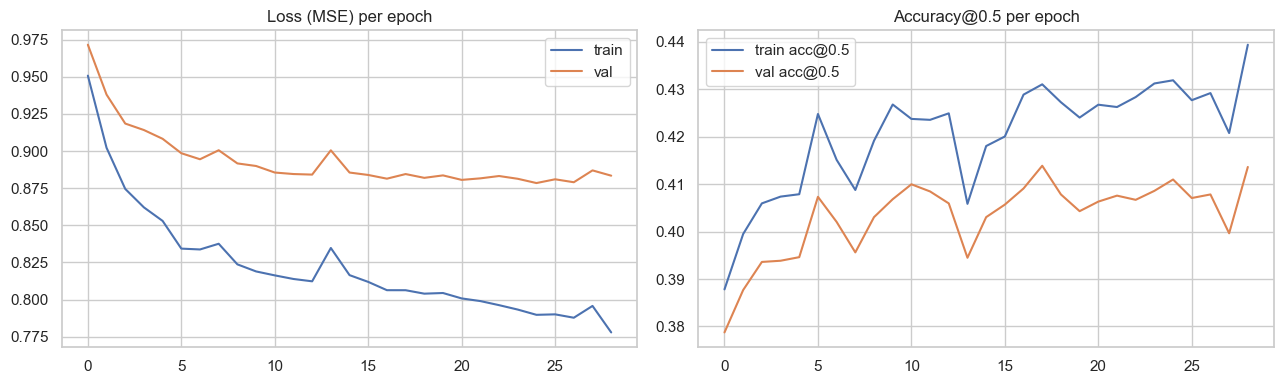

In [17]:
perm = np.random.permutation(len(u_tr))
n_val = int(0.1 * len(u_tr))
va_idx, tr_idx = perm[:n_val], perm[n_val:]

x_all = (pd.DataFrame(pf_full.transform(train), columns=pf_full.feature_names_)[stat_cols].values
         - stat_mean) / stat_std

mlp_model, mlp_hist = train_mlp(u_tr[tr_idx], i_tr[tr_idx], x_all[tr_idx], r_tr[tr_idx],
                                u_tr[va_idx], i_tr[va_idx], x_all[va_idx], r_tr[va_idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(mlp_hist['train_loss'], label='train')
axes[0].plot(mlp_hist['val_loss'], label='val')
axes[0].set_title('Loss (MSE) per epoch')
axes[0].legend()
axes[1].plot(mlp_hist['train_acc'], label='train acc@0.5')
axes[1].plot(mlp_hist['val_acc'], label='val acc@0.5')
axes[1].set_title('Accuracy@0.5 per epoch')
axes[1].legend()
plt.tight_layout()
plt.show()


def mlp_predict(X):
    u = np.array([mf.umap_[u_] for u_ in X['user_id']])
    i = np.array([mf.imap_[i_] for i_ in X['item_id']])
    x = (pd.DataFrame(pf_full.transform(X), columns=pf_full.feature_names_)[stat_cols].values
         - stat_mean) / stat_std
    mlp_model.eval()
    with torch.no_grad():
        p = mlp_model(torch.from_numpy(u), torch.from_numpy(i),
                      torch.from_numpy(x.astype('float32'))).numpy()
    return np.clip(p, 1, 5)

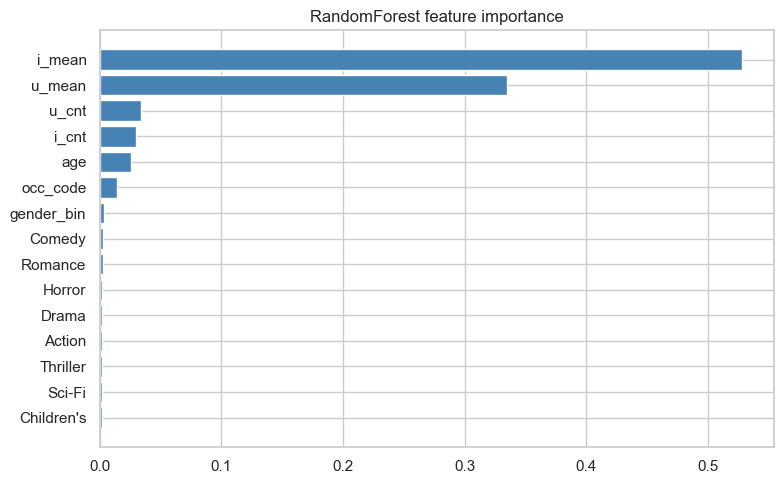

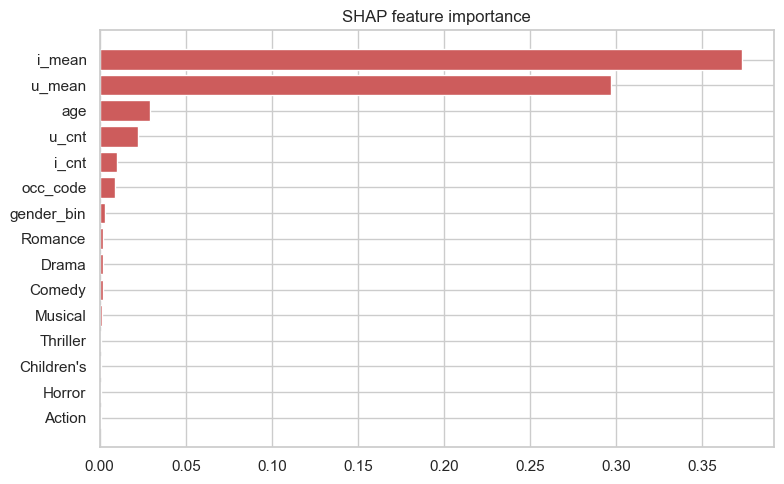

In [19]:
rf_model = fitted['RandomForest']
names = rf_model.named_steps['feat'].feature_names_
imp = rf_model.named_steps['clf'].feature_importances_
order = np.argsort(-imp)[:15]
plt.figure(figsize=(8, 5))
plt.barh([names[k] for k in order][::-1], imp[order][::-1], color='steelblue')
plt.title('RandomForest feature importance')
plt.tight_layout()
plt.show()


import shap
Xf = pf_full.transform(train)
explainer = shap.TreeExplainer(rf_model.named_steps['clf'])
sv = explainer.shap_values(Xf[np.random.choice(len(Xf), 500, replace=False)])
gi = np.abs(sv).mean(0)
o = np.argsort(-gi)[:15]
plt.figure(figsize=(8, 5))
plt.barh([names[k] for k in o][::-1], gi[o][::-1], color='indianred')
plt.title('SHAP feature importance')
plt.tight_layout()
plt.show()


In [20]:
models = {
    'GlobalMean': gm.predict,
    'UserBasedCF': UserBasedCF.predict,
    'ItemBasedCF': ItemBasedCF.predict,
    'ContentRidge': fitted['ContentRidge'].predict,
    'Ridge': fitted['Ridge'].predict,
    'DecisionTree': fitted['DecisionTree'].predict,
    'RandomForest': fitted['RandomForest'].predict,
    'MatrixFactorization': mf.predict,
    'MLP': mlp_predict,
}

def blend_predict(X):
    return (models['MatrixFactorization'](X) + models['MLP'](X) +
            models['RandomForest'](X)) / 3
models['Blend'] = blend_predict

rows = []
for name, fn in models.items():
    p = np.clip(fn(test), 1, 5)
    row = {'model': name, 'RMSE': rmse(test['rating'], p)}
    if name == 'GlobalMean':
        row['Precision@10'] = np.nan
        row['NDCG@10'] = np.nan
    else:
        row['Precision@10'], row['NDCG@10'] = ranking_metrics(fn)
    rows.append(row)
    print(row)

results_df = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
print()
print(results_df.to_string(index=False))

{'model': 'GlobalMean', 'RMSE': 1.1237710165237664, 'Precision@10': nan, 'NDCG@10': nan}
{'model': 'UserBasedCF', 'RMSE': 1.0622287511349675, 'Precision@10': 0.006, 'NDCG@10': 0.006556500735139692}
{'model': 'ItemBasedCF', 'RMSE': 0.9904790877191404, 'Precision@10': 0.005, 'NDCG@10': 0.006459729300459478}
{'model': 'ContentRidge', 'RMSE': 1.106968808886527, 'Precision@10': 0.0285, 'NDCG@10': 0.032743491759386546}
{'model': 'Ridge', 'RMSE': 0.9508305432621115, 'Precision@10': 0.0525, 'NDCG@10': 0.0481931104115227}
{'model': 'DecisionTree', 'RMSE': 0.9514480332483003, 'Precision@10': 0.047, 'NDCG@10': 0.055305629511602124}
{'model': 'RandomForest', 'RMSE': 0.9382439195371546, 'Precision@10': 0.0665, 'NDCG@10': 0.07880333470499462}
{'model': 'MatrixFactorization', 'RMSE': 1.7994079490712338, 'Precision@10': 0.027000000000000003, 'NDCG@10': 0.030278239667441687}
{'model': 'MLP', 'RMSE': 0.9427367183282833, 'Precision@10': 0.034, 'NDCG@10': 0.03196608682966874}
{'model': 'Blend', 'RMSE': 1.